<a href="https://colab.research.google.com/github/sileysa/Semester_5/blob/main/JS07/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import library dan membaca dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()
nama_file = next(iter(uploaded))

df = pd.read_csv(nama_file)

print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima data pertama:")
display(df.head())

print("\nInformasi dataset:")
df.info()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset (1).csv
Ukuran dataset: (660, 7)

Nama kolom:
['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Lima data pertama:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


# Cek data kosong dan duplikat

In [2]:
print("Jumlah data kosong setiap kolom:")
print(df.isnull().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())

print("\nStatistik data numerik:")
display(df.describe())

Jumlah data kosong setiap kolom:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64

Jumlah baris duplikat: 0

Statistik data numerik:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


# Menentukan variabel dan menyiapkan data

In [3]:
# Menyamakan huruf kecil dan besar serta mengabaikan spasi
kolom_normal = {
    kolom.strip().lower().replace(" ", "_"): kolom
    for kolom in df.columns
}

# Mencari dua kolom yang dibutuhkan untuk scatterplot
kandidat_avg = ["avg_credit_limit"]
kandidat_kartu = [
    "total_credit_card",
    "total_credit_cards"
]

kolom_avg = next(
    (kolom_normal[k] for k in kandidat_avg if k in kolom_normal),
    None
)

kolom_kartu = next(
    (kolom_normal[k] for k in kandidat_kartu if k in kolom_normal),
    None
)

if kolom_avg is None or kolom_kartu is None:
    raise ValueError(
        "Nama kolom tidak ditemukan. Periksa df.columns.tolist()."
    )

print("Kolom batas kredit rata-rata:", kolom_avg)
print("Kolom total kartu kredit:", kolom_kartu)

# Salinan data untuk analisis
data = df.copy()

# Menghapus kolom ID jika ada
kolom_id = [
    c for c in data.columns
    if c.strip().lower() in [
        "customer_id", "customer key", "customer_key", "id"
    ]
]

data = data.drop(columns=kolom_id, errors="ignore")

# Mengubah kolom kategorikal menjadi numerik jika tersedia
data = pd.get_dummies(data, drop_first=True, dtype=int)

# Mengubah nilai tak hingga menjadi NaN
data = data.replace([np.inf, -np.inf], np.nan)

# Mengisi data kosong dengan median setiap kolom
data = data.fillna(data.median(numeric_only=True))

# Menghapus kolom yang konstan
data = data.loc[:, data.nunique() > 1]

print("Ukuran data untuk klasterisasi:", data.shape)
display(data.head())

Kolom batas kredit rata-rata: Avg_Credit_Limit
Kolom total kartu kredit: Total_Credit_Cards
Ukuran data untuk klasterisasi: (660, 6)


,Sl_No,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,100000,2,1,1,0
1,2,50000,3,0,10,9
2,3,50000,7,1,3,4
3,4,30000,5,1,1,4
4,5,100000,6,0,12,3


# Membuat scatterplot

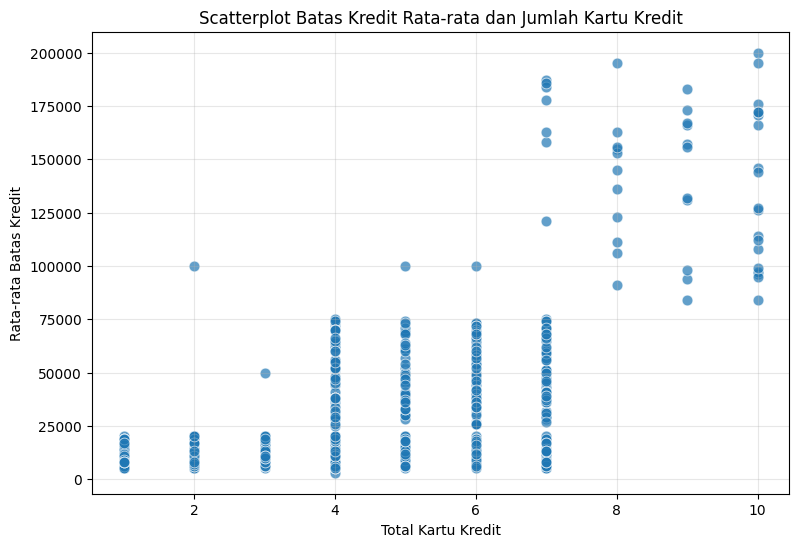

In [4]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x=kolom_kartu,
    y=kolom_avg,
    s=60,
    alpha=0.7
)

plt.title("Scatterplot Batas Kredit Rata-rata dan Jumlah Kartu Kredit")
plt.xlabel("Total Kartu Kredit")
plt.ylabel("Rata-rata Batas Kredit")
plt.grid(alpha=0.3)
plt.show()

# Menghitung korelasi untuk membantu analisis linearitas

In [5]:
korelasi = df[[kolom_kartu, kolom_avg]].corr().iloc[0, 1]

print(f"Koefisien korelasi Pearson: {korelasi:.4f}")

if korelasi > 0.7:
    print("Hubungan linear positif relatif kuat.")
elif korelasi > 0.3:
    print("Hubungan linear positif sedang.")
elif korelasi >= -0.3:
    print("Hubungan linear relatif lemah.")
elif korelasi >= -0.7:
    print("Hubungan linear negatif sedang.")
else:
    print("Hubungan linear negatif relatif kuat.")

Koefisien korelasi Pearson: 0.6089
Hubungan linear positif sedang.


# Standardisasi data

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)

print("Ukuran data setelah standardisasi:", X_scaled.shape)

Ukuran data setelah standardisasi: (660, 6)


# Menghitung inertia untuk beberapa nilai \(k\)

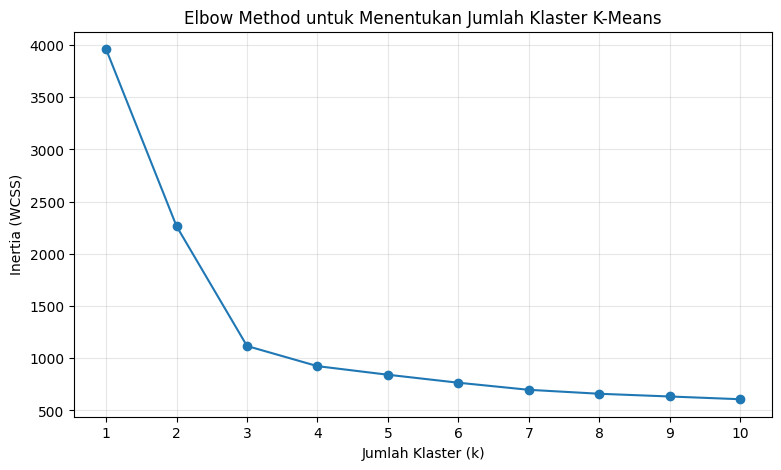

In [7]:
from sklearn.cluster import KMeans

inertia_values = []
rentang_k = range(1, 11)

for k in rentang_k:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(
    list(rentang_k),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method untuk Menentukan Jumlah Klaster K-Means")
plt.xlabel("Jumlah Klaster (k)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(rentang_k))
plt.grid(alpha=0.3)
plt.show()

# Membuat model K-Means dan menentukan label klaster

In [8]:
k_terbaik = 3  # Ganti sesuai hasil Elbow Method

kmeans = KMeans(
    n_clusters=k_terbaik,
    random_state=42,
    n_init=10
)

label_kmeans = kmeans.fit_predict(X_scaled)

df_kmeans = df.copy()
df_kmeans["Cluster_KMeans"] = label_kmeans

print("Jumlah klaster:", k_terbaik)
print("\nJumlah nasabah setiap klaster:")
print(df_kmeans["Cluster_KMeans"].value_counts().sort_index())

display(df_kmeans.head())

Jumlah klaster: 3

Jumlah nasabah setiap klaster:
Cluster_KMeans
0    384
1     50
2    226
Name: count, dtype: int64


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Cluster_KMeans
0,1,87073,100000,2,1,1,0,2
1,2,38414,50000,3,0,10,9,2
2,3,17341,50000,7,1,3,4,2
3,4,40496,30000,5,1,1,4,2
4,5,47437,100000,6,0,12,3,1


# Visualisasi klaster

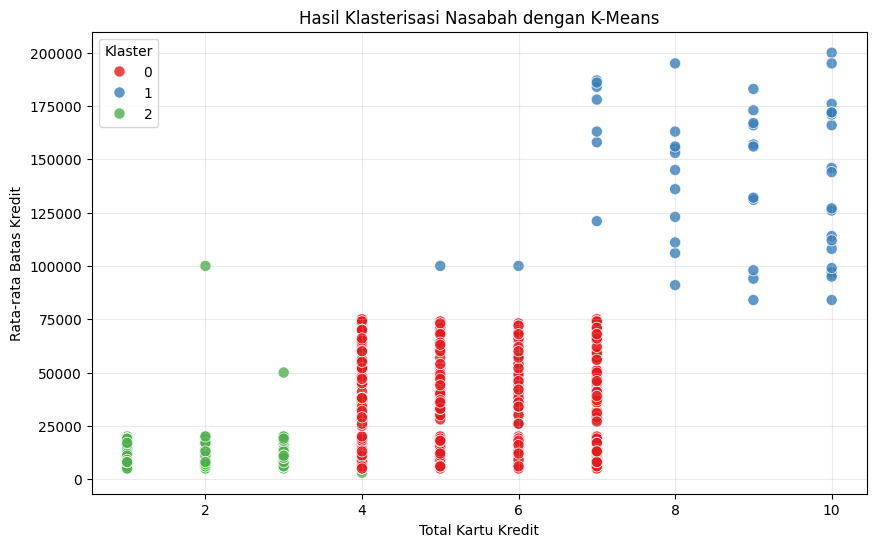

In [9]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_kmeans,
    x=kolom_kartu,
    y=kolom_avg,
    hue="Cluster_KMeans",
    palette="Set1",
    s=65,
    alpha=0.8
)

plt.title("Hasil Klasterisasi Nasabah dengan K-Means")
plt.xlabel("Total Kartu Kredit")
plt.ylabel("Rata-rata Batas Kredit")
plt.legend(title="Klaster")
plt.grid(alpha=0.25)
plt.show()

# Melihat karakteristik tiap klaster

In [10]:
print("Rata-rata karakteristik nasabah per klaster:")
display(
    df_kmeans.groupby("Cluster_KMeans")[data.columns.tolist()]
    .mean()
    .round(2)
)

Rata-rata karakteristik nasabah per klaster:


,Sl_No,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster_KMeans,,,,,,
0,420.50,33507.81,5.52,3.51,0.98,2.00
1,611.28,141040.00,8.74,0.60,10.90,1.08
2,115.46,12831.86,2.43,0.93,3.54,6.83


# Membuat grafik k-distance untuk membantu memilih eps

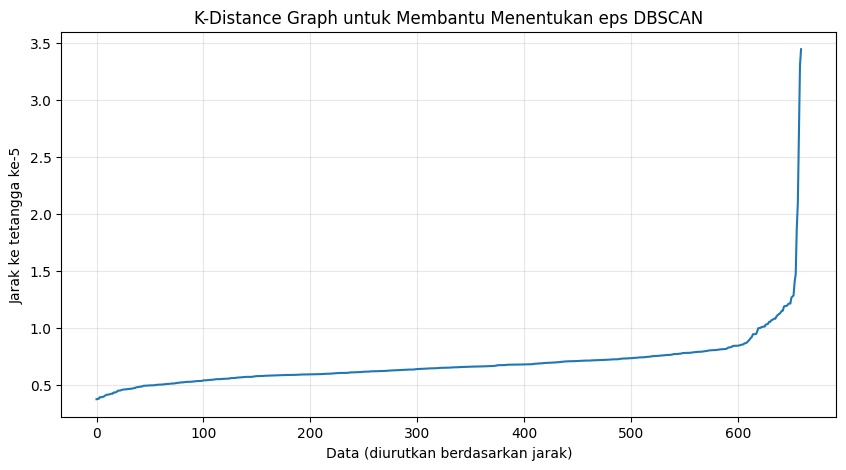

In [11]:
from sklearn.neighbors import NearestNeighbors

min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Jarak ke tetangga ke-min_samples, diurutkan dari kecil ke besar
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(k_distances)

plt.title("K-Distance Graph untuk Membantu Menentukan eps DBSCAN")
plt.xlabel("Data (diurutkan berdasarkan jarak)")
plt.ylabel(f"Jarak ke tetangga ke-{min_samples}")
plt.grid(alpha=0.3)
plt.show()

# Menjalankan DBSCAN

In [12]:
from sklearn.cluster import DBSCAN

eps_terpilih = 1.5  # Sesuaikan berdasarkan grafik k-distance

dbscan = DBSCAN(
    eps=eps_terpilih,
    min_samples=min_samples
)

label_dbscan = dbscan.fit_predict(X_scaled)

df_dbscan = df.copy()
df_dbscan["Cluster_DBSCAN"] = label_dbscan

jumlah_cluster = len(set(label_dbscan) - {-1})
jumlah_noise = np.sum(label_dbscan == -1)

print("Nilai eps:", eps_terpilih)
print("Nilai min_samples:", min_samples)
print("Jumlah klaster DBSCAN:", jumlah_cluster)
print("Jumlah data noise:", jumlah_noise)

print("\nJumlah data setiap label:")
print(df_dbscan["Cluster_DBSCAN"].value_counts().sort_index())

display(df_dbscan.head())

Nilai eps: 1.5
Nilai min_samples: 5
Jumlah klaster DBSCAN: 2
Jumlah data noise: 4

Jumlah data setiap label:
Cluster_DBSCAN
-1      4
 0    608
 1     48
Name: count, dtype: int64


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Cluster_DBSCAN
0,1,87073,100000,2,1,1,0,-1
1,2,38414,50000,3,0,10,9,-1
2,3,17341,50000,7,1,3,4,0
3,4,40496,30000,5,1,1,4,0
4,5,47437,100000,6,0,12,3,-1


# Scatterplot klaster DBSCAN

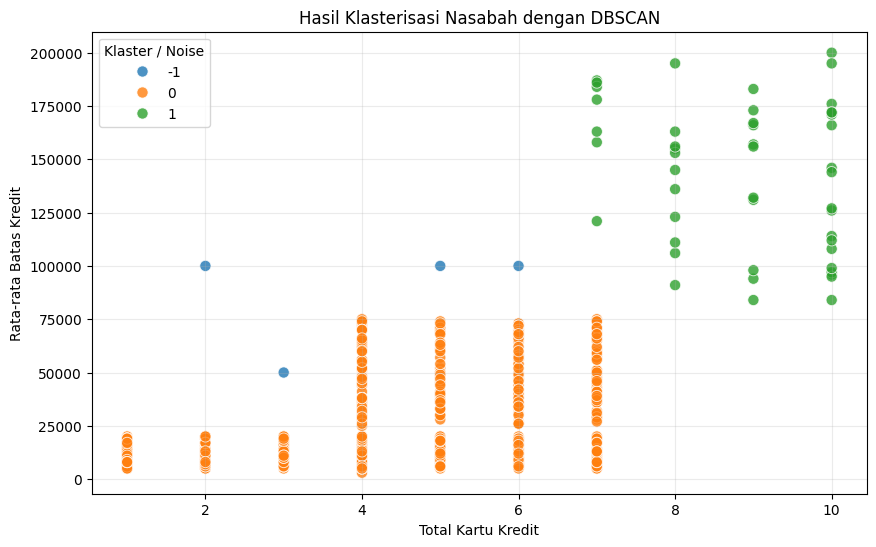

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_dbscan,
    x=kolom_kartu,
    y=kolom_avg,
    hue="Cluster_DBSCAN",
    palette="tab10",
    s=65,
    alpha=0.8
)

plt.title("Hasil Klasterisasi Nasabah dengan DBSCAN")
plt.xlabel("Total Kartu Kredit")
plt.ylabel("Rata-rata Batas Kredit")
plt.legend(title="Klaster / Noise")
plt.grid(alpha=0.25)
plt.show()

# Menghitung kedua metrik

In [14]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Abaikan data noise untuk evaluasi klaster DBSCAN
mask = label_dbscan != -1

X_evaluasi = X_scaled[mask]
label_evaluasi = label_dbscan[mask]

jumlah_data_dinilai = len(label_evaluasi)
jumlah_cluster_dinilai = len(np.unique(label_evaluasi))

print("Jumlah data yang dievaluasi:", jumlah_data_dinilai)
print("Jumlah klaster yang dievaluasi:", jumlah_cluster_dinilai)
print("Jumlah data noise:", np.sum(label_dbscan == -1))

if jumlah_cluster_dinilai >= 2 and jumlah_cluster_dinilai < jumlah_data_dinilai:
    silhouette = silhouette_score(X_evaluasi, label_evaluasi)
    dbi = davies_bouldin_score(X_evaluasi, label_evaluasi)

    print(f"\nSilhouette Score: {silhouette:.4f}")
    print(f"Davies-Bouldin Index (DBI): {dbi:.4f}")
else:
    print(
        "\nMetrik tidak dapat dihitung dengan benar: "
        "diperlukan minimal 2 klaster dan jumlah klaster "
        "harus lebih kecil daripada jumlah data yang dievaluasi."
    )

Jumlah data yang dievaluasi: 656
Jumlah klaster yang dievaluasi: 2
Jumlah data noise: 4

Silhouette Score: 0.5510
Davies-Bouldin Index (DBI): 0.6330


### Kesimpulan

Berdasarkan hasil praktikum klasterisasi data nasabah kartu kredit, diperoleh korelasi Pearson sebesar 0,6089 antara variabel jumlah kartu kredit dan rata-rata batas kredit. Hasil tersebut menunjukkan hubungan linear positif dengan kekuatan sedang.

Pada algoritma K-Means, Elbow Method menunjukkan titik siku di sekitar tiga klaster sehingga nilai \(k=3\) dipilih sebagai jumlah klaster yang digunakan. Pemilihan tersebut didasarkan pada penurunan inertia yang signifikan hingga tiga klaster dan penurunan yang semakin kecil setelahnya.

Sementara itu, algoritma DBSCAN dengan parameter `eps = 1.5` dan `min_samples = 5` menghasilkan dua klaster utama, yaitu 608 nasabah pada klaster 0 dan 48 nasabah pada klaster 1, serta empat data noise. Evaluasi terhadap data non-noise menghasilkan Silhouette Score sebesar 0,5510 dan Davies-Bouldin Index sebesar 0,6330.

Secara keseluruhan, kedua algoritma dapat digunakan untuk mengelompokkan nasabah berdasarkan kemiripan karakteristiknya. K-Means memerlukan penentuan jumlah klaster terlebih dahulu, sedangkan DBSCAN membentuk klaster berdasarkan kepadatan data dan dapat mengidentifikasi data noise.